In [1]:
import numpy as np
import matplotlib.pyplot as plt
from petitRADTRANS.physics import madhu_seager_2009

In [20]:
press = np.logspace(-6, 3, 100)  # Pressure in bar
offset = np.log10(press[0])

log_p3 = 2 - offset
log_p2 = log_p3 * (1.0 - 0.5)
log_p1 = log_p2 * (1.0 - 0.5)
pressure_points = [np.log10(press[0]), (log_p1 + offset), (log_p2 + offset), (log_p3 + offset), 3]
print(pressure_points)
alpha_points=[-0.1,0.1]
beta_points=[0.5,0.5]
T_set=4000
temperature = madhu_seager_2009(
    press,
    pressure_points,
    T_set,
    alpha_points,
    beta_points)

[-6.0, -4.0, -2.0, 2.0, 3]


(1000.0, 1e-06)

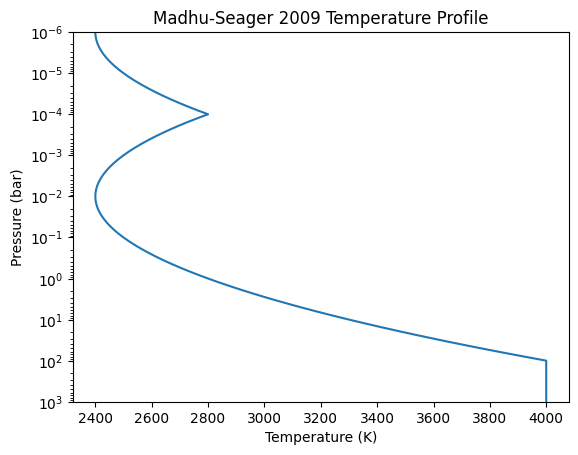

In [21]:
plt.plot(temperature,press, label='Madhu-Seager 2009')
plt.yscale('log')
plt.ylabel('Pressure (bar)')
plt.xlabel('Temperature (K)')
plt.title('Madhu-Seager 2009 Temperature Profile')
plt.ylim(1e3, 1e-6)

(1000.0, 1e-06)

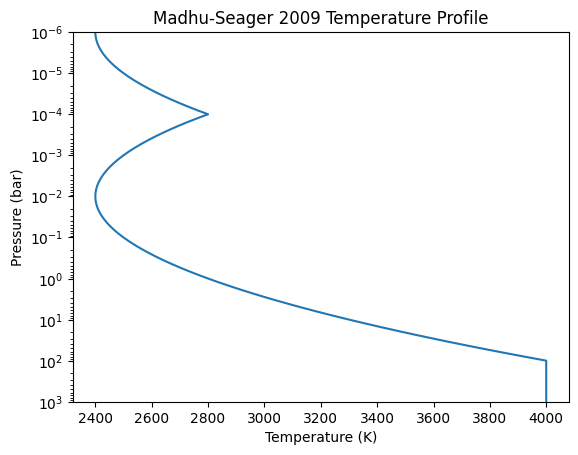

In [13]:
def compute_T_Madhu(P, a1, a2, log_P1, log_P2, log_P3, T_set, P_set):
    '''
    Computes the temperature profile for an atmosphere using a re-arranged
    form of the P-T profile parametrisation in Madhusudhan & Seager (2009).

    Args:
        P (np.array of float):
            Atmosphere pressure array (bar).
        a1 (float):
            Alpha_1 parameter (encodes slope in layer 1).
        a2 (float):
            Alpha_2 parameter encodes slope in layer 2).
        log_P1 (float):
            Pressure of layer 1-2 boundary.
        log_P2 (float):
            Pressure of inversion.
        log_P3 (float):
            Pressure of layer 2-3 boundary.
        T_set (float):
            Atmosphere temperature reference value at P = P_set (K).
        P_set (float):
            Pressure whether the temperature parameter T_set is defined (bar).
    
    Returns:
        T (3D np.array of float):
            Temperature of each layer as a function of pressure (K). 
            Only the first axis is used for this 1D profile.
    
    '''

    # Store number of layers for convenience
    N_layers = len(P)
    
    # Initialise temperature array
    T = np.zeros(shape=(N_layers, 1, 1)) # 1D profile => N_sectors = N_zones = 1
    
    # Find index of pressure closest to the set pressure
    i_set = np.argmin(np.abs(P - P_set))
    P_set_i = P[i_set]
    
    # Store logarithm of various pressure quantities
    log_P = np.log10(P)
    log_P_min = np.log10(np.min(P))
    log_P_set_i = np.log10(P_set_i)

    # By default (P_set = 10 bar), so T(P_set) should be in layer 3
    if (log_P_set_i >= log_P3):
        
        T3 = T_set  # T_deep is the isothermal deep temperature T3 here
        
        # Use the temperature parameter to compute boundary temperatures
        T2 = T3 - ((1.0/a2)*(log_P3 - log_P2))**2    
        T1 = T2 + ((1.0/a2)*(log_P1 - log_P2))**2    
        T0 = T1 - ((1.0/a1)*(log_P1 - log_P_min))**2   
        
    # If a different P_deep has been chosen, solve equations for layer 2...
    elif (log_P_set_i >= log_P1):   # Temperature parameter in layer 2
        
        # Use the temperature parameter to compute the boundary temperatures
        T2 = T_set - ((1.0/a2)*(log_P_set_i - log_P2))**2
        T1 = T2 + ((1.0/a2)*(log_P1 - log_P2))**2
        T3 = T2 + ((1.0/a2)*(log_P3 - log_P2))**2
        T0 = T1 - ((1.0/a1)*(log_P1 - log_P_min))**2   
        
    # ...or for layer 1
    elif (log_P_set_i < log_P1):  # Temperature parameter in layer 1
    
        # Use the temperature parameter to compute the boundary temperatures
        T0 = T_set - ((1.0/a1)*(log_P_set_i - log_P_min))**2
        T1 = T0 + ((1.0/a1)*(log_P1 - log_P_min))**2   
        T2 = T1 - ((1.0/a2)*(log_P1 - log_P2))**2  
        T3 = T2 + ((1.0/a2)*(log_P3 - log_P2))**2
        
    # Compute temperatures within each layer
    for i in range(N_layers):
        
        if (log_P[i] >= log_P3):
            T[i,0,0] = T3
        elif ((log_P[i] < log_P3) and (log_P[i] > log_P1)):
            T[i,0,0] = T2 + np.power(((1.0/a2)*(log_P[i] - log_P2)), 2.0)
        elif (log_P[i] <= log_P1):
            T[i,0,0] = T0 + np.power(((1.0/a1)*(log_P[i] - log_P_min)), 2.0)

    return T

temperature = compute_T_Madhu(
    press,
    alpha_points[0],
    alpha_points[1],
    pressure_points[1],
    pressure_points[2],
    pressure_points[3],
    T_set,
    10**pressure_points[4]).flatten()

plt.plot(temperature,press, label='Madhu-Seager 2009')
plt.yscale('log')
plt.ylabel('Pressure (bar)')
plt.xlabel('Temperature (K)')
plt.title('Madhu-Seager 2009 Temperature Profile')
plt.ylim(1e3, 1e-6)